# Notebook 7 – Outlier Analysis

Detect, **investigate and document** outliers. Outliers are *not* automatically removed.

**Sprint 4 – Data Inspection & Exploratory Data Analysis**  
Workflow: `Load → Inspect → Understand → Analyze → Visualize → Identify Problems → Document Findings`  
**Dataset:** Telco Customer Churn (IBM sample data, 7,043 customers × 21 columns)

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

# Load the RAW dataset (nothing has been modified yet).
# This loader checks common local locations first, then tries the public source.
from pathlib import Path

TELCO_URLS = [
    "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv",
    "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/main/data/Telco-Customer-Churn.csv",
]

candidate_names = [
    "telco.csv",
    "Telco-Customer-Churn.csv",
    "WA_Fn-UseC_-Telco-Customer-Churn.csv",
]

search_roots = [Path.cwd(), *list(Path.cwd().parents)[:4]]
local_candidates = []
for root in search_roots:
    for name in candidate_names:
        local_candidates.extend([
            root / name,
            root / "data" / name,
            root / "Datasets" / name,
            root / "dataset" / name,
        ])

local_path = next((p.resolve() for p in local_candidates if p.is_file()), None)

if local_path is not None:
    df_raw = pd.read_csv(local_path)
    print("Loaded local dataset:", local_path)
else:
    load_errors = []
    df_raw = None
    for url in TELCO_URLS:
        try:
            df_raw = pd.read_csv(url)
            print("Loaded dataset from public source.")
            break
        except Exception as exc:
            load_errors.append(f"{url} -> {type(exc).__name__}: {exc}")
    if df_raw is None:
        raise FileNotFoundError(
            "Could not find the Telco dataset locally, and downloading it failed. "
            "Place the original Telco Customer Churn CSV in a 'data' folder next to "
            "your notebooks (or in the parent folder's 'data' folder), name it "
            "'telco.csv' or 'Telco-Customer-Churn.csv', and rerun this cell. "
            "If using a URL, check your internet connection.\n\nDetails:\n"
            + "\n".join(load_errors)
        )

df = df_raw.copy()
print("Loaded:", df.shape)


# NOTE: 'TotalCharges' is stored as text in the raw file (11 blank strings, see 03_Data_Quality).
# For ANALYSIS ONLY we create a numeric working copy; blanks become NaN. The raw file is untouched,
# and the formal treatment of these rows is deferred to the preprocessing sprint.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in df.columns if c not in num_cols + ["customerID"]]
target = "Churn"
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)   # helper for rates/correlations (analysis only)

Loaded: (7043, 21)


### Topic Explanation

This topic identifies unusually distant observations, compares detection methods, and considers whether they are errors or meaningful cases.

## 1. What is an Outlier? Why do they occur? Types

**Definition:** an observation that lies far away from the bulk of the data.

**Why they occur:** (1) data-entry or measurement error, (2) system/processing bug, (3) a different population (e.g. corporate vs individual customer), (4) natural rare extremes (e.g. a very heavy user), (5) sampling issues.

**Types**
* **Point (global) outliers** – an extreme value in one variable.  
* **Contextual outliers** – normal overall but abnormal in context (e.g. 35 °C in winter).  
* **Collective outliers** – a group of observations that together is abnormal.  
* **Univariate outliers** – extreme in a single variable (IQR / Z-score / box plot).  
* **Multivariate outliers** – each value looks normal alone, but the *combination* is unusual (scatter plot, Mahalanobis distance).

**ML relevance:** outliers can distort the mean/std, skew linear model coefficients, dominate distance-based models and scaling – but may also *be* the signal (fraud, failures).

### Topic Explanation

This topic focuses on demonstration of iqr vs z-score on synthetic data. Read the existing notes, follow the example cells, and explain what the resulting output tells you.

## 2. Demonstration of IQR vs Z-score on synthetic data

### 1. Concept
**IQR method:** outlier if x < Q1 – 1.5·IQR or x > Q3 + 1.5·IQR (robust, based on quartiles).  
**Z-score method:** z = (x – μ)/σ; outlier if |z| > 3 (assumes roughly normal data; μ and σ are themselves influenced by outliers).

### 2. Example
*Simple:* salaries of 20 employees plus the CEO's salary.  
*Business:* a single order of \$1,000,000 among \$50 orders.  
*AI/ML use:* choosing the right rule avoids removing valid data or missing real anomalies.

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

IQR fences: 37.5 62.0
IQR outliers : [5.0, 64.6, 95.0, 100.0]
Z-score (|z|>3) outliers: [5.0, 95.0, 100.0]


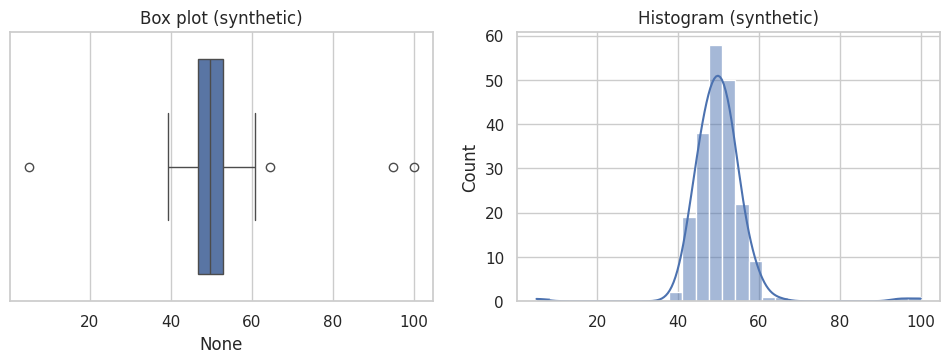

In [2]:
rng = np.random.default_rng(42)
data = np.append(rng.normal(50, 5, 200), [95, 100, 5])           # 3 planted outliers
s = pd.Series(data)

q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
iqr_out = s[(s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)]
z = (s - s.mean()) / s.std()
z_out = s[z.abs() > 3]
print("IQR fences:", round(q1 - 1.5 * iqr, 1), round(q3 + 1.5 * iqr, 1))
print("IQR outliers :", sorted(iqr_out.round(1)))
print("Z-score (|z|>3) outliers:", sorted(z_out.round(1)))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
sns.boxplot(x=s, ax=ax[0]); ax[0].set_title("Box plot (synthetic)")
sns.histplot(s, kde=True, ax=ax[1]); ax[1].set_title("Histogram (synthetic)")
plt.show()

### 5. Interpretation
Both methods detect the three planted extremes (5, 95 and 100). The IQR rule additionally flags one natural tail value (≈ 64.6), i.e. it is slightly more sensitive; the Z-score rule flags only the three extreme points. The Z-score works well here because the data is truly normal with few outliers.

### 6. Insight
IQR is more robust for skewed data; Z-score can be inflated by the outliers themselves (masking effect).

### 7. AI/ML Relevance
Knowing both rules and when each fails is part of defensible outlier handling.

### Topic Explanation

This topic studies one variable at a time to understand its values, distribution, centre, spread, and frequency.

## 3. Univariate Outliers on the Telco Data – IQR Method

### 1. Concept
Apply the IQR rule to every numerical column and count flagged rows.

### 2. Example
Same idea as above, applied to `tenure`, `MonthlyCharges`, `TotalCharges`.

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

In [3]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return q1 - k * i, q3 + k * i

rows = []
for c in num_cols:
    s = df[c].dropna()
    lo, hi = iqr_bounds(s)
    out = s[(s < lo) | (s > hi)]
    rows.append((c, round(lo, 1), round(hi, 1), s.min(), s.max(), len(out), f"{len(out)/len(s):.2%}"))
display(pd.DataFrame(rows, columns=["column", "lower_fence", "upper_fence", "min", "max", "n_outliers", "pct"]))

,column,lower_fence,upper_fence,min,max,n_outliers,pct
0,tenure,-60.0,124.0,0.00,72.00,0,0.00%
1,MonthlyCharges,-46.0,171.4,18.25,118.75,0,0.00%
2,TotalCharges,-4688.5,8884.7,18.80,8684.80,0,0.00%


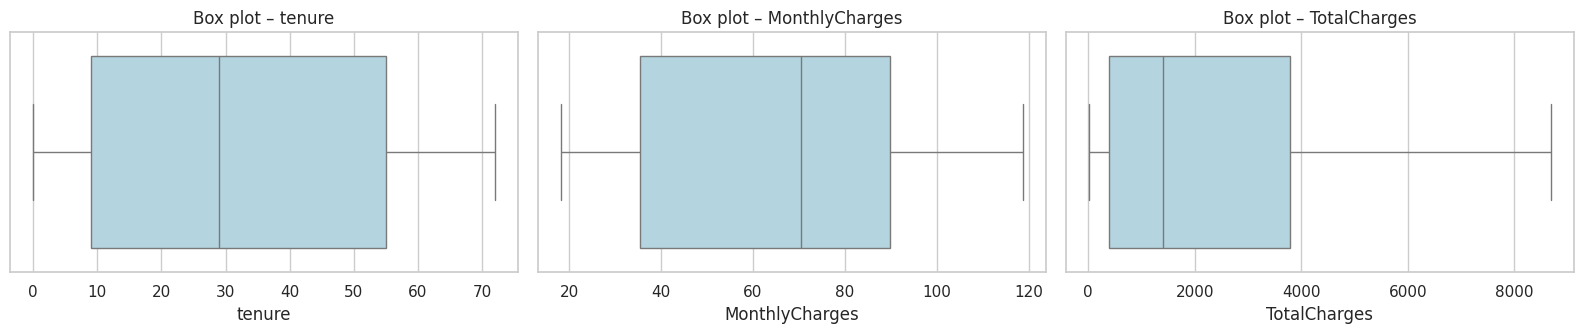

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))
for ax, c in zip(axes, num_cols):
    sns.boxplot(x=df[c], ax=ax, color="lightblue"); ax.set_title(f"Box plot – {c}")
plt.tight_layout(); plt.show()

### 5. Interpretation
**The IQR rule flags zero rows in all three columns**: every value lies inside the fences (e.g. `TotalCharges` max ≈ 8,685 versus an upper fence ≈ 8,884), and the box plots show no points beyond the whiskers.

### 6. Insight
Univariate outliers are *absent* here. The long right tail of `TotalCharges` is a natural consequence of long tenure × high price, not an error.

### 7. AI/ML Relevance
No univariate outlier treatment is needed for this dataset; applying it anyway would only remove valid long-term, high-value customers.

### Topic Explanation

This topic focuses on z-score method. Read the existing notes, follow the example cells, and explain what the resulting output tells you.

## 4. Z-Score Method

### 1. Concept
Flag |z| > 3 (strict) and |z| > 2.5 (more sensitive); compare with IQR.

### 2. Example
Same as above using mean and standard deviation.

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

In [5]:
rows = []
for c in num_cols:
    s = df[c].dropna()
    z = stats.zscore(s)
    rows.append((c, int((np.abs(z) > 3).sum()), int((np.abs(z) > 2.5).sum()), round(np.abs(z).max(), 2)))
display(pd.DataFrame(rows, columns=["column", "|z|>3", "|z|>2.5", "max |z|"]))

,column,|z|>3,|z|>2.5,max |z|
0,tenure,0,0,1.61
1,MonthlyCharges,0,0,1.79
2,TotalCharges,0,90,2.82


### 5. Interpretation
No value exceeds |z| = 3 (max |z|: tenure 1.6, MonthlyCharges 1.8, TotalCharges 2.8). Only `TotalCharges` crosses the more sensitive 2.5 level, for about 90 customers (≈ 1.3%).

### 6. Insight
Both methods agree: nothing extreme under the standard thresholds. The ≈ 90 customers beyond |z| > 2.5 in `TotalCharges` are the long-tenure, high-price customers at the end of the right tail – valid and valuable.

### 7. AI/ML Relevance
When two independent methods agree, we can be confident in the conclusion. Z-score would be less reliable on the skewed `TotalCharges`, which is why IQR is the primary method here.

### Topic Explanation

This topic identifies unusually distant observations, compares detection methods, and considers whether they are errors or meaningful cases.

## 5. Derived-feature outliers (Spending-behaviour check)

### 1. Concept
An outlier may hide in a *derived* quantity. Compare `TotalCharges / tenure` (actual average spend per month) with `MonthlyCharges` (current price). Large gaps indicate a plan change or discount.

### 2. Example
*Business:* a customer who now pays \$100/month but averaged \$30 historically upgraded recently.

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

avg_monthly_spend  fences=(-44.8, 171.2)  IQR outliers=0 (0.00%)
spend_gap_pct      fences=(-7.9, 8.1)  IQR outliers=625 (8.89%)


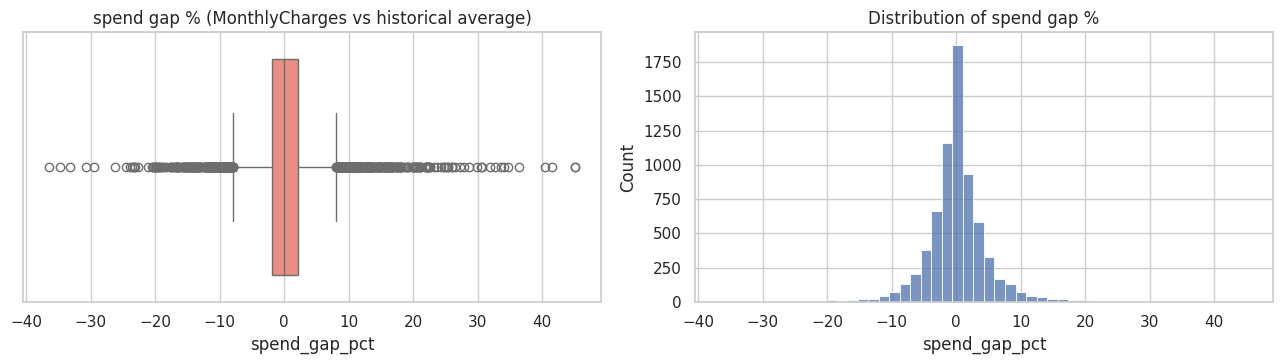

,customerID,tenure,MonthlyCharges,TotalCharges,avg_monthly_spend,spend_gap_pct,Churn
2950,3345-JHUEO,4,20.2,55.7,13.9,45.1,No
4203,4291-YZODP,7,20.0,96.8,13.8,45.0,No
900,1051-GEJLJ,2,19.5,27.6,13.8,41.6,No
4262,5485-WUYWF,2,66.4,94.6,47.3,40.5,Yes
5595,2308-STERM,2,19.4,61.0,30.5,-36.4,No


In [6]:
d = df[df.tenure > 0].copy()
d["avg_monthly_spend"] = d["TotalCharges"] / d["tenure"]
d["spend_gap_pct"] = (d["MonthlyCharges"] - d["avg_monthly_spend"]) / d["avg_monthly_spend"] * 100

for c in ["avg_monthly_spend", "spend_gap_pct"]:
    lo, hi = iqr_bounds(d[c]); out = d[(d[c] < lo) | (d[c] > hi)]
    print(f"{c:<18} fences=({lo:.1f}, {hi:.1f})  IQR outliers={len(out)} ({len(out)/len(d):.2%})")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
sns.boxplot(x=d["spend_gap_pct"], ax=axes[0], color="salmon"); axes[0].set_title("spend gap % (MonthlyCharges vs historical average)")
sns.histplot(d["spend_gap_pct"], bins=50, ax=axes[1]); axes[1].set_title("Distribution of spend gap %")
plt.tight_layout(); plt.show()

display(d.loc[d["spend_gap_pct"].abs().sort_values(ascending=False).index[:5],
              ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "avg_monthly_spend", "spend_gap_pct", "Churn"]].round(1))

### 5. Interpretation
`avg_monthly_spend` has no IQR outliers, but `spend_gap_pct` flags about 625 customers (≈ 9%). Their median tenure is only about 7 months: with so few billing cycles, a first partial month, a promotion or a recent plan change makes `TotalCharges / tenure` differ noticeably from today's price. The most extreme rows have tenures of only 2–7 months.

### 6. Insight
These are **valid but unusual observations** (billing timing, plan upgrades or discounts), not data-entry errors. They are informative: a large positive gap means a recent upgrade, which might relate to churn.

### 7. AI/ML Relevance
Derived-feature outliers should usually be *kept and possibly turned into a feature* (e.g. `price_change_flag`), rather than deleted.

### Topic Explanation

This topic examines several variables together to identify combined patterns, correlations, and interactions.

## 6. Multivariate Outliers – Scatter Plot and Mahalanobis Distance

### 1. Concept
Mahalanobis distance measures how far a point is from the centre of the multivariate distribution, accounting for correlations. Under normality D² follows a χ² distribution with *p* degrees of freedom; a cut-off at the 99.9th percentile flags unusual combinations.

### 2. Example
*Simple:* height 190 cm and weight 45 kg – each plausible alone, but unusual together.  
*Business:* high tenure but very low total billing.  
*AI/ML use:* finds anomalies that univariate rules miss.

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

chi2 cut-off at 95.0% (df=3): 7.81  ->  355 rows flagged
chi2 cut-off at 99.0% (df=3): 11.34  ->  61 rows flagged
chi2 cut-off at 99.9% (df=3): 16.27  ->  0 rows flagged

Inspecting the 61 rows beyond the 99% cut-off (0.87% of customers)


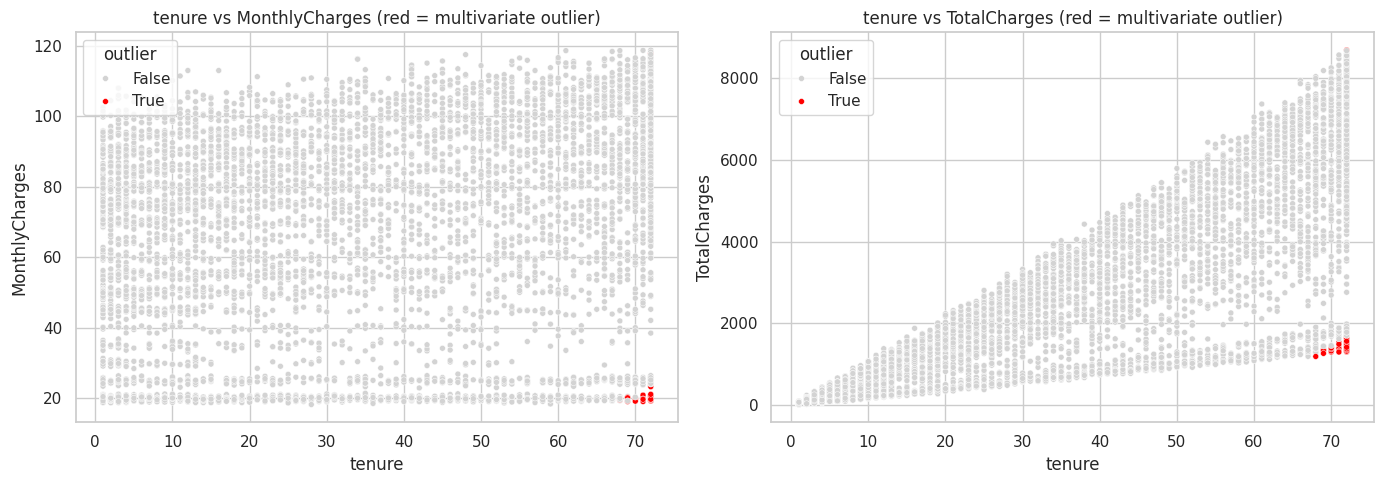

In [7]:
X = df[num_cols].dropna()
mu = X.mean().values
cov_inv = np.linalg.inv(np.cov(X.values, rowvar=False))
diff = X.values - mu
md2 = np.einsum("ij,jk,ik->i", diff, cov_inv, diff)          # squared Mahalanobis distance
for q in (0.95, 0.99, 0.999):
    cut = stats.chi2.ppf(q, df=X.shape[1])
    print(f"chi2 cut-off at {q:.1%} (df={X.shape[1]}): {cut:.2f}  ->  {int((md2 > cut).sum())} rows flagged")
cutoff = stats.chi2.ppf(0.99, df=X.shape[1])      # 99% level used for inspection
flag = md2 > cutoff
print(f"\nInspecting the {int(flag.sum())} rows beyond the 99% cut-off ({flag.mean():.2%} of customers)")

plot = X.assign(md2=md2, outlier=flag)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=plot, x="tenure", y="MonthlyCharges", hue="outlier", palette={False: "lightgray", True: "red"}, s=18, ax=axes[0])
axes[0].set_title("tenure vs MonthlyCharges (red = multivariate outlier)")
sns.scatterplot(data=plot, x="tenure", y="TotalCharges", hue="outlier", palette={False: "lightgray", True: "red"}, s=18, ax=axes[1])
axes[1].set_title("tenure vs TotalCharges (red = multivariate outlier)")
plt.tight_layout(); plt.show()

In [8]:
display(df.loc[X.index[flag], ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract", "InternetService", "Churn"]].head(10))
print("Churn rate among flagged:", df.loc[X.index[flag], "ChurnFlag"].mean().round(3) if flag.any() else "n/a")
print("\nProfile of flagged rows:")
display(df.loc[X.index[flag], ["tenure", "MonthlyCharges", "TotalCharges"]].describe().round(0).T)
print(df.loc[X.index[flag], "InternetService"].value_counts().to_dict())

,customerID,tenure,MonthlyCharges,TotalCharges,Contract,InternetService,Churn
109,2848-YXSMW,72,19.40,1363.25,Two year,No,No
233,7083-MIOPC,72,20.25,1566.90,Two year,No,No
316,3973-SKMLN,71,19.90,1355.10,Two year,No,No
347,8966-SNIZF,70,19.45,1303.50,Two year,No,No
405,7606-BPHHN,72,19.80,1468.75,Two year,No,No
497,0505-SPOOW,70,19.80,1397.65,Two year,No,No
531,1403-GYAFU,70,20.05,1360.25,Two year,No,No
714,4312-KFRXN,72,25.40,1710.90,Two year,No,No
932,5787-KXGIY,72,19.30,1304.80,Two year,No,No
984,8165-ZJRNM,72,23.75,1679.25,Two year,No,No


Churn rate among flagged: 0.016

Profile of flagged rows:


,count,mean,std,min,25%,50%,75%,max
tenure,61.0,71.0,1.0,68.0,71.0,72.0,72.0,72.0
MonthlyCharges,61.0,22.0,13.0,19.0,20.0,20.0,20.0,118.0
TotalCharges,61.0,1543.0,935.0,1194.0,1363.0,1411.0,1492.0,8685.0


{'No': 60, 'Fiber optic': 1}


### 5. Interpretation
At the strict 99.9% level **no customer** is a multivariate outlier; at the 99% level 61 customers (≈ 0.9%) are flagged. Almost all of them have been customers for 68–72 months on the cheapest ≈ \$20 plan (60 of 61 have no internet service), so their `TotalCharges` (≈ \$1,200–1,500) is modest compared with other 72-month customers. Their `TotalCharges` still equals `tenure × MonthlyCharges` almost exactly, and only 1.6% of them churned.

### 6. Insight
These points are **valid unusual observations**: they follow the billing logic and are simply a distinct segment (very loyal, very cheap, phone-only customers). They are *unusual in combination*, not wrong.

### 7. AI/ML Relevance
Multivariate outliers matter most for distance-based and linear models. Because they are valid, keep them and prefer robust models/scaling instead of deleting.

### Topic Explanation

This topic identifies unusually distant observations, compares detection methods, and considers whether they are errors or meaningful cases.

## 7. Decision Framework – What to do with outliers

### 1. Concept
For every candidate outlier ask: *Is it genuine? an entry error? unusual but valid?* Then decide: **remove / transform / retain**. Document the reasoning.

### 2. Example
Like a judge: evidence first, verdict second.

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

In [9]:
decision = pd.DataFrame([
    ["tenure", "None by IQR/Z-score", "Genuine; spikes at 1 and 72 are real/cap effects", "Retain", "Consider binning later"],
    ["MonthlyCharges", "None", "Genuine price range of plans", "Retain", "Scale if model needs it"],
    ["TotalCharges", "None (long right tail)", "Genuine: long tenure × high price", "Retain", "Log transform optional for linear models"],
    ["tenure = 0 rows (11)", "Boundary values", "Valid new customers; TotalCharges blank", "Retain", "Fix TotalCharges to 0"],
    ["avg spend gap", "Some IQR outliers", "Valid: billing timing / upgrades", "Retain", "Could create 'price_change' feature"],
    ["Mahalanobis flags", "0 at 99.9%; 61 at 99%", "Valid: loyal, cheap, phone-only customers", "Retain", "Keep as a segment; tree models / robust scaling"],
], columns=["Item", "Detected?", "Assessment", "Decision", "Notes"])
decision

,Item,Detected?,Assessment,Decision,Notes
0,tenure,None by IQR/Z-score,Genuine; spikes at 1 and 72 are real/cap effects,Retain,Consider binning later
1,MonthlyCharges,None,Genuine price range of plans,Retain,Scale if model needs it
2,TotalCharges,None (long right tail),Genuine: long tenure × high price,Retain,Log transform optional for linear models
3,tenure = 0 rows (11),Boundary values,Valid new customers; TotalCharges blank,Retain,Fix TotalCharges to 0
4,avg spend gap,Some IQR outliers,Valid: billing timing / upgrades,Retain,Could create 'price_change' feature
5,Mahalanobis flags,0 at 99.9%; 61 at 99%,"Valid: loyal, cheap, phone-only customers",Retain,Keep as a segment; tree models / robust scaling


### 5. Interpretation
Every detected case was assessed as genuine or valid-unusual; none was a data-entry error. The recommended decision is **retain** everywhere.

### 6. Insight
Removing these points would delete high-value, long-tenure customers and distort the business picture; documenting *why* shows analytical maturity.

### 7. AI/ML Relevance
Blind removal of outliers can drop the very customers a model must learn from; transformation or robust methods are the safer defaults.